# Evaluación y Comparación de Modelos
Evaluación comparativa unificada de los 4 modelos entrenados.

In [1]:
# CELDA 1: Cargar librerías y datos de test
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    classification_report, roc_auc_score, f1_score,
    precision_score, recall_score, confusion_matrix,
    roc_curve, precision_recall_curve,
    matthews_corrcoef, average_precision_score
)
import tensorflow as tf

X_test    = np.load('../data/processed/X_test.npy')
X_test_sc = np.load('../data/processed/X_test_sc.npy')
y_test    = np.load('../data/processed/y_test.npy')

print('Test dataset shape:', X_test.shape)
print('Fraud cases in test:', y_test.sum())

Test dataset shape: (65824, 12)
Fraud cases in test: 1232


In [2]:
# CELDA 2: Cargar los modelos entrenados
modelo_if  = joblib.load('../models/isolation_forest.pkl')
modelo_rf  = joblib.load('../models/random_forest.pkl')
modelo_xgb = joblib.load('../models/xgboost.pkl')
autoenc    = tf.keras.models.load_model('../models/autoencoder.h5', compile=False)
ae_cfg     = joblib.load('../models/autoencoder_config.pkl')

In [3]:
# CELDA 3: Obtener predicciones de los 4 modelos
# Isolation Forest
pred_if_raw = modelo_if.predict(X_test)
y_if        = np.where(pred_if_raw == -1, 1, 0)
scores_if   = -modelo_if.score_samples(X_test)

# Random Forest
y_rf        = modelo_rf.predict(X_test)
scores_rf   = modelo_rf.predict_proba(X_test)[:,1]

# XGBoost
y_xgb       = modelo_xgb.predict(X_test)
scores_xgb  = modelo_xgb.predict_proba(X_test)[:,1]

# Autoencoder
recon      = autoenc.predict(X_test_sc, verbose=0)
errores_ae = np.mean(np.power(X_test_sc - recon, 2), axis=1)
y_ae       = (errores_ae > ae_cfg['umbral']).astype(int)

print('Predicciones obtenidas con éxito.')

Predicciones obtenidas con éxito.


In [4]:
# CELDA 4: Calcular y mostrar métricas consolidadas
def calcular_metricas(nombre, y_true, y_pred, scores):
    return {
        'Modelo':          nombre,
        'Precision':       round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall':          round(recall_score(y_true, y_pred), 4),
        'F1-Score':        round(f1_score(y_true, y_pred), 4),
        'AUC-ROC':         round(roc_auc_score(y_true, scores), 4),
        'PR-AUC':          round(average_precision_score(y_true, scores), 4),
        'MCC':             round(matthews_corrcoef(y_true, y_pred), 4),
        'Falsos Neg. (%)': round((((y_true==1)&(y_pred==0)).sum() / (y_true==1).sum())*100, 2),
    }

resultados = pd.DataFrame([
    calcular_metricas('Isolation Forest', y_test, y_if,  scores_if),
    calcular_metricas('Random Forest',    y_test, y_rf,  scores_rf),
    calcular_metricas('XGBoost',          y_test, y_xgb, scores_xgb),
    calcular_metricas('Autoencoder',      y_test, y_ae,  errores_ae),
])
resultados = resultados.set_index('Modelo')
print('\n===== TABLA COMPARATIVA DE MODELOS =====')
print(resultados.to_string())

# Guardar tabla de métricas en formato csv para cargar en app de Streamlit
import os
os.makedirs('../data/processed', exist_ok=True)
resultados.to_csv('../data/processed/comparacion_modelos.csv')


===== TABLA COMPARATIVA DE MODELOS =====
                  Precision  Recall  F1-Score  AUC-ROC  PR-AUC     MCC  Falsos Neg. (%)
Modelo                                                                                 
Isolation Forest     0.0820  0.0041    0.0077   0.7772  0.0712  0.0142            99.59
Random Forest        0.9976  0.9992    0.9984   1.0000  1.0000  0.9983             0.08
XGBoost              0.9960  0.9992    0.9976   1.0000  1.0000  0.9975             0.08
Autoencoder          0.1020  0.2979    0.1520   0.7936  0.0847  0.1478            70.21


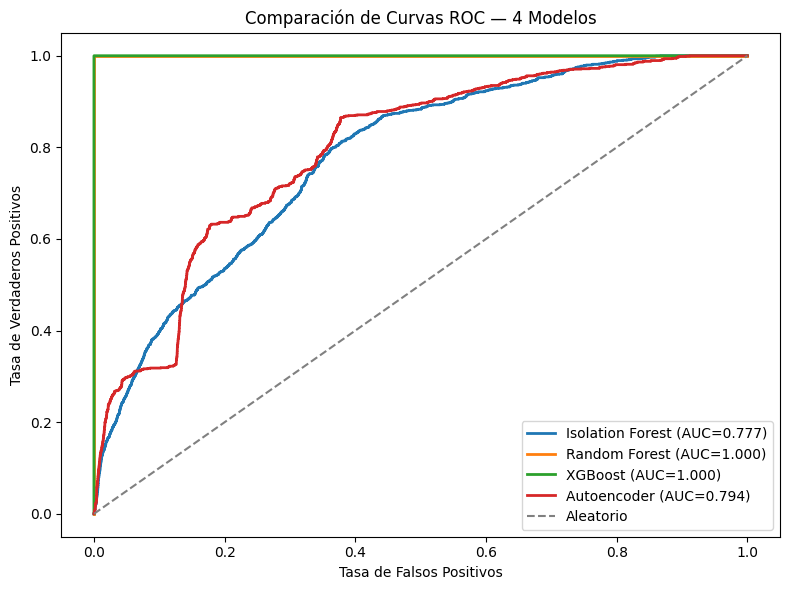

In [5]:
# CELDA 5: Gráfica 1 - Curvas ROC
plt.figure(figsize=(8,6))
for nombre, y_pred, scores in [
    ('Isolation Forest', y_if,  scores_if),
    ('Random Forest',    y_rf,  scores_rf),
    ('XGBoost',          y_xgb, scores_xgb),
    ('Autoencoder',      y_ae,  errores_ae),
]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC={auc:.3f})', lw=2)

plt.plot([0,1],[0,1],'--', color='gray', label='Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Comparación de Curvas ROC — 4 Modelos')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../notebooks/fig_curvas_roc.png', dpi=150)
plt.show()

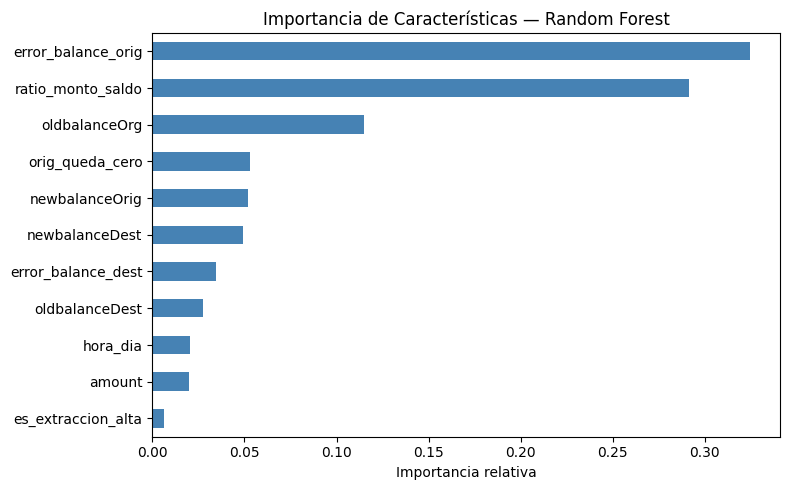

In [6]:
# CELDA 6: Gráfica 2 - Importancia de Características (Random Forest)
features = [
    'amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest',
    'error_balance_orig','error_balance_dest','orig_queda_cero',
    'ratio_monto_saldo','es_extraccion_alta','hora_dia'
]

importancias = pd.Series(
    modelo_rf.feature_importances_[:len(features)], index=features
).sort_values(ascending=True)

plt.figure(figsize=(8,5))
importancias.plot(kind='barh', color='steelblue')
plt.title('Importancia de Características — Random Forest')
plt.xlabel('Importancia relativa')
plt.tight_layout()
plt.savefig('../notebooks/fig_importancia_features.png', dpi=150)
plt.show()

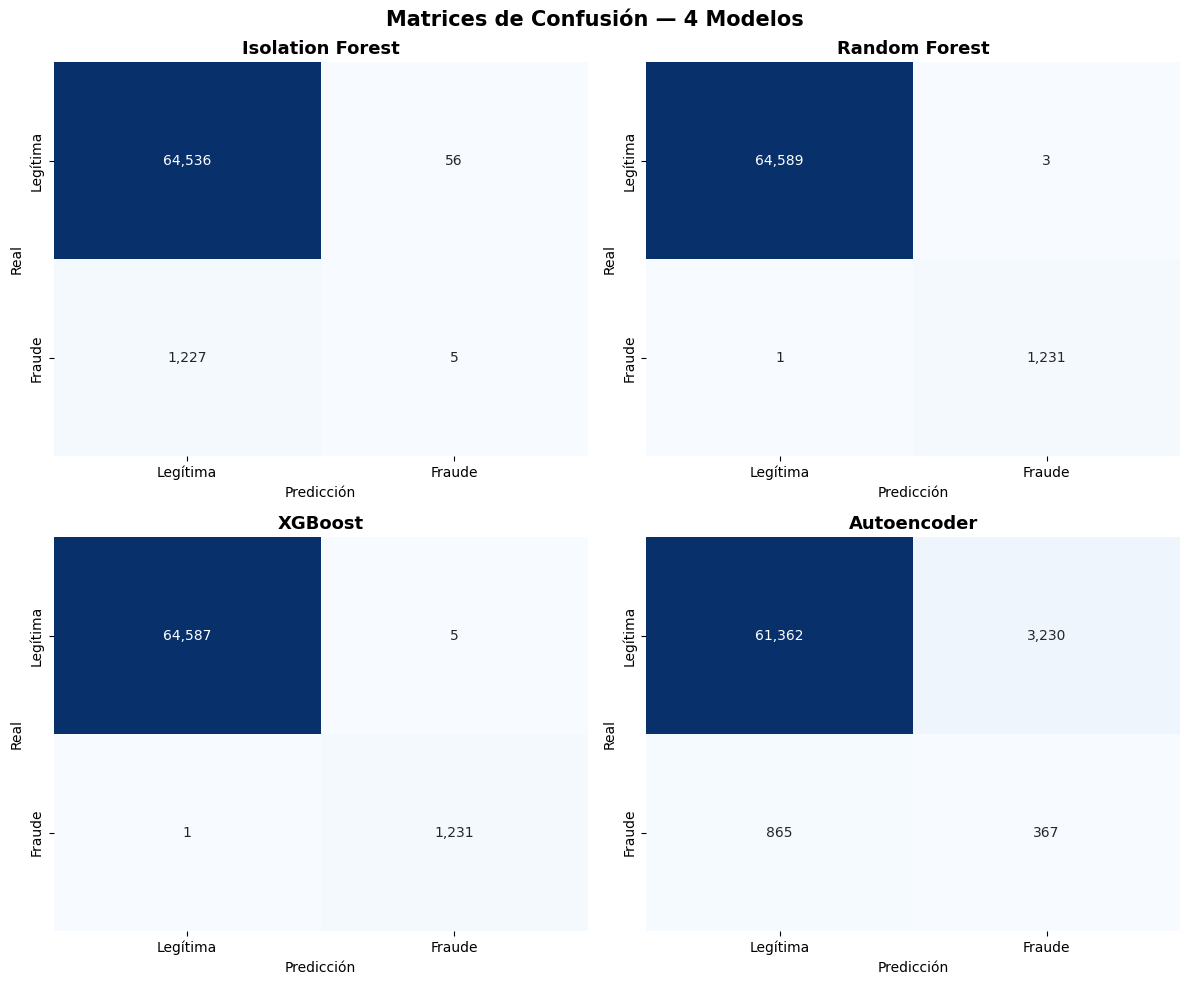

In [7]:
# CELDA 7: Gráfica 3 - Matrices de confusión de 4 paneles
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
modelos_cm = [
    ('Isolation Forest', y_if),
    ('Random Forest',    y_rf),
    ('XGBoost',          y_xgb),
    ('Autoencoder',      y_ae),
]
for ax, (nombre, y_pred) in zip(axes.flatten(), modelos_cm):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues',
                ax=ax, cbar=False,
                xticklabels=['Legítima','Fraude'],
                yticklabels=['Legítima','Fraude'])
    ax.set_title(nombre, fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')
plt.suptitle('Matrices de Confusión — 4 Modelos', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../notebooks/fig_matrices_confusion.png', dpi=150)
plt.show()